In [1]:
pip install h5py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 29.8 MB/s  0:00:00

[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [17]:
spectra = "Datasets/1P/1P_1_0/SPECTRA_000.hdf5"

In [18]:
# See structure of the file
def show_structure(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(f"DATASET: {name}  shape={obj.shape}  dtype={obj.dtype}")
    else:
        print(f"GROUP:   {name}")

with h5py.File(spectra, "r") as f:
    f.visititems(show_structure)

GROUP:   Header
GROUP:   colden
GROUP:   colden/H
DATASET: colden/H/1  shape=(5000, 3633)  dtype=float64
GROUP:   density_weight_density
GROUP:   num_important
GROUP:   spectra
DATASET: spectra/axis  shape=(5000,)  dtype=int32
DATASET: spectra/cofm  shape=(5000, 3)  dtype=float64
GROUP:   tau
GROUP:   tau/H
GROUP:   tau/H/1
DATASET: tau/H/1/1215  shape=(5000, 3633)  dtype=float64
GROUP:   tau_obs
GROUP:   temperature
GROUP:   velocity


## Key pieces

* `tau/H/1/1215`: Optical depth of HI at Lya (1215 Angstroms), shape `(sightline, pixel)`
* `colden/H/1`: HI column density per pixel for each sightline
* `spectra/cofm`: (x,yx) position of each sighline in the simulation box
* `spectra/axis`: Axis of each sighline (1, 2, or 3)
* `Header`: Attributes like redshift and box size, not a dataset.

In [19]:
with h5py.File(spectra, "r") as f:
    tau = f["tau/H/1/1215"][:]     # (5000, 3633)
    colden = f["colden/H/1"][:]    # (5000, 3633)
    cofm = f["spectra/cofm"][:]    # (5000, 3)
    axis = f["spectra/axis"][:]    # (5000,)

    # Header info lives in attributes
    header = dict(f["Header"].attrs)

print(header)

{'box': np.float64(25000.0), 'discarded': np.int64(0), 'hubble': np.float64(0.6711), 'nbins': np.int64(3633), 'npart': array([16732425, 16777216,        0,        0,     7667,       44],
      dtype=uint64), 'omegab': np.float64(0.048976552745069714), 'omegal': np.float64(0.7), 'omegam': np.float64(0.3), 'redshift': np.float64(5.994167484881114)}


## Convert $\tau$ to transmitted flux and plot a few sightlines

Use $F = e^{-\tau}$

* flux = 1 means no absorption
* flux = 0 means fully absorbed

Redshift: 5.99e+00
Global mean flux: 1.66e-04


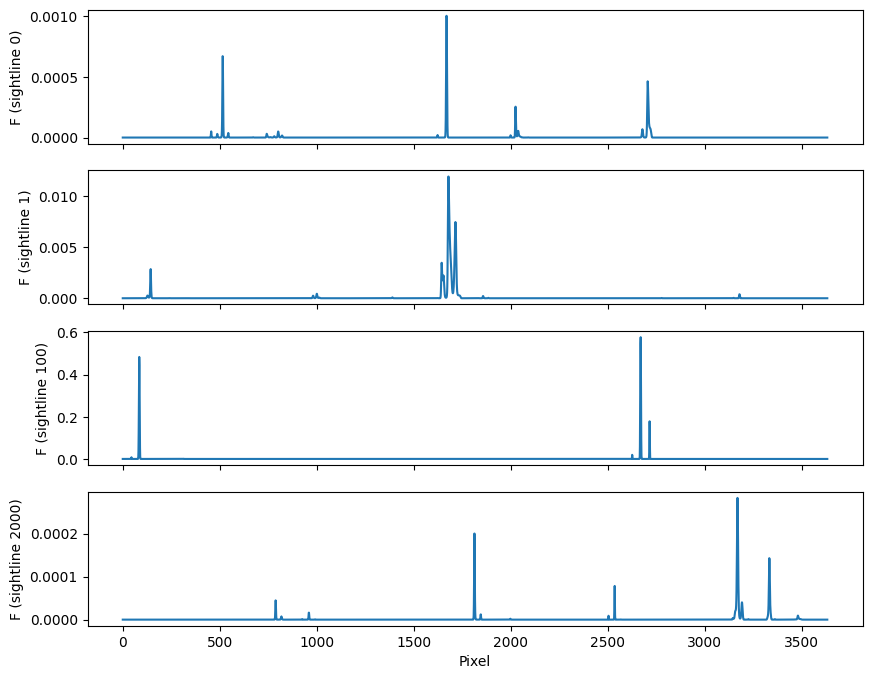

In [20]:
flux = np.exp(-tau)

print(f"Redshift: {header.get("redshift"):.2e}")
print(f"Global mean flux: {flux.mean():.2e}")

# Compare a few sightlines
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, i in zip(axes, [0, 1, 100, 2000]):
    ax.plot(flux[i])
    ax.set_ylabel(f"F (sightline {i})")
axes[-1].set_xlabel("Pixel")
plt.show()

## Plot optical depth

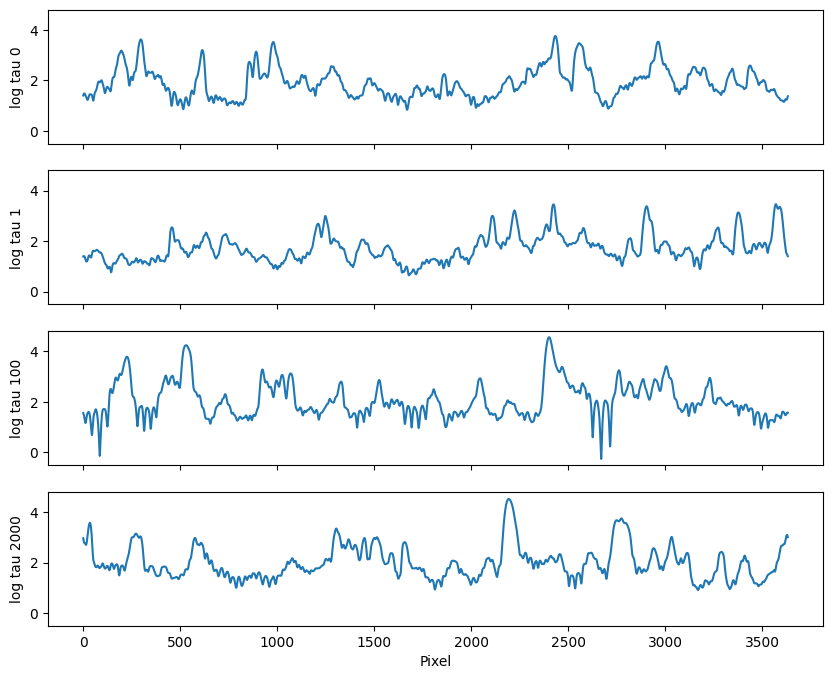

In [21]:
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, i in zip(axes, [0, 1, 100, 2000]):
    ax.plot(np.log10(tau[i]))
    ax.set_ylabel(f"log tau {i}")
axes[-1].set_xlabel("Pixel")
plt.show()

## Plot column density

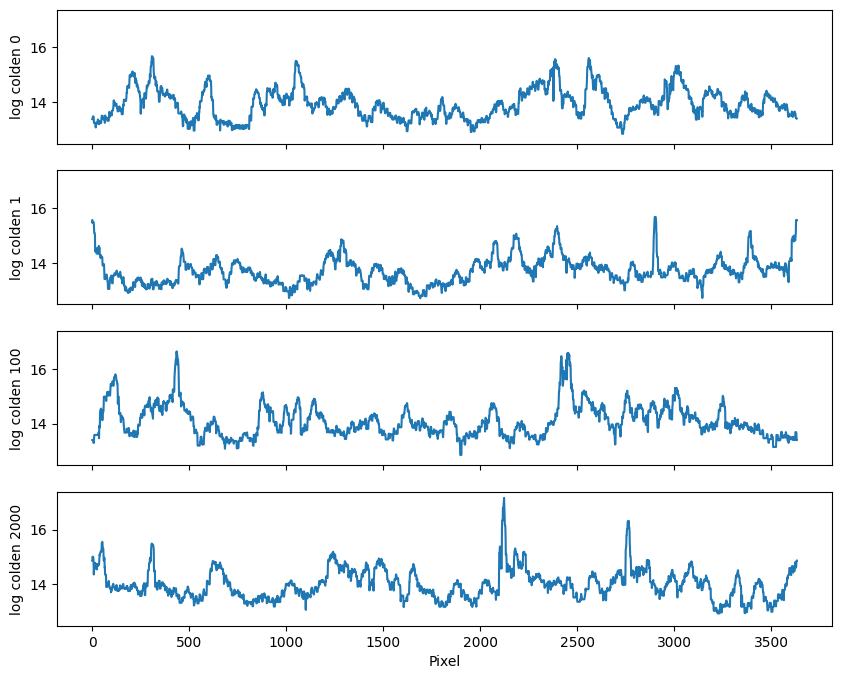

In [22]:
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, i in zip(axes, [0, 1, 100, 2000]):
    ax.plot(np.log10(colden[i]))
    ax.set_ylabel(f"log colden {i}")
axes[-1].set_xlabel("Pixel")
plt.show()

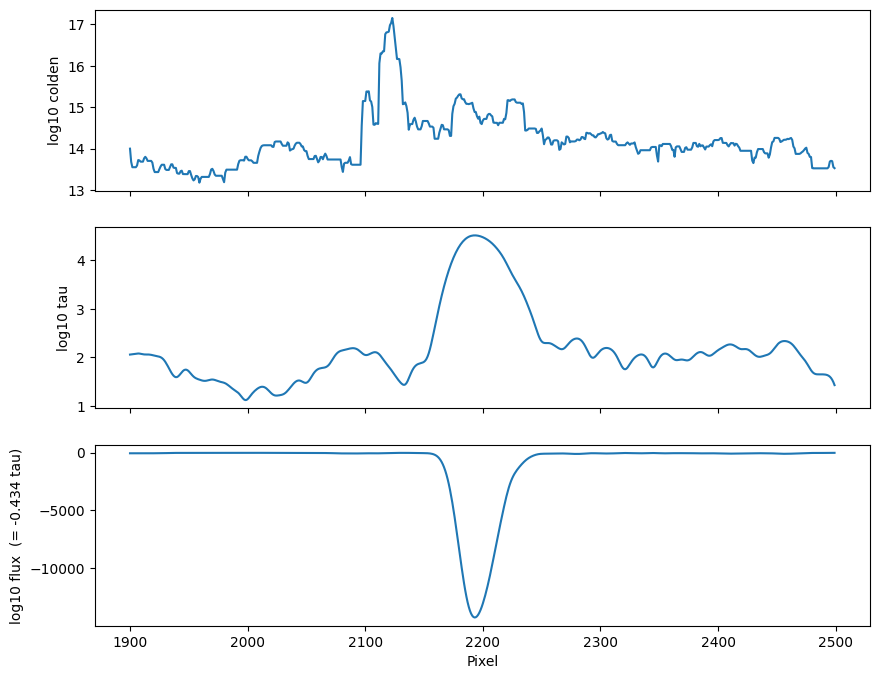

In [23]:
lo, hi = 1900, 2500
x = np.arange(lo, hi)

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(x, np.log10(colden[2000][lo:hi]))
ax[0].set_ylabel("log10 colden")

ax[1].plot(x, np.log10(tau[2000][lo:hi]))
ax[1].set_ylabel("log10 tau")

#F = exp(-tau) --> log10(F) = -tau * log10(e)
ax[2].plot(x, -tau[2000][lo:hi] * np.log10(np.e))
ax[2].set_ylabel("log10 flux  (= -0.434 tau)")
ax[2].set_xlabel("Pixel")
plt.show()